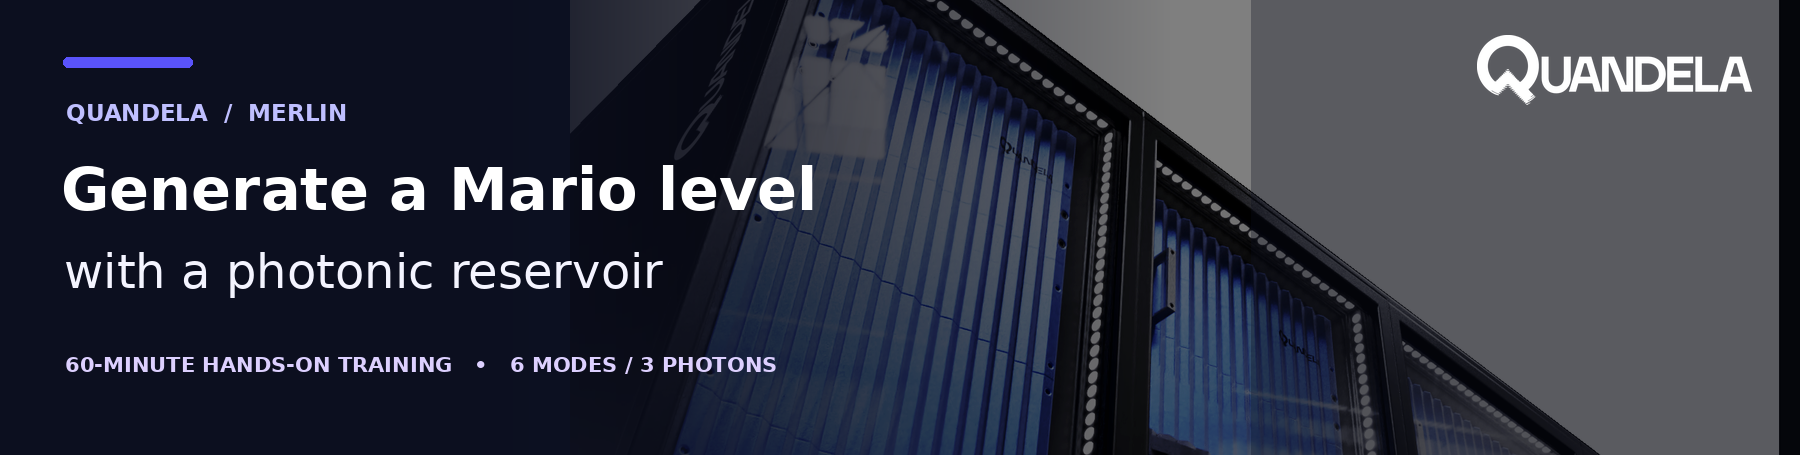

# MerLin × Quantum Reservoir Computing
### Mario level generation with a photonic reservoir · **60-minute hands-on training**

**Goal:** discover how MerLin can be used as a *fixed* quantum feature extractor inside a very small sequence-generation model. We will build a photonic reservoir, train **only a classical readout**, generate new Mario levels, and ask whether the levels are both novel and coherent.

**Audience:** people comfortable with basic Python and machine learning. No quantum-computing prerequisites.

**Learning outcomes**
1. Understand `token + memory → photonic reservoir → probabilities → readout → next token`.
2. Build a MerLin `CircuitBuilder` and wrap it in a `QuantumLayer`.
3. Explain why the photonic circuit is **not trained**, while the linear readout is.
4. Generate levels with a temperature parameter and compare two simple baselines.

> **Scientific scope.** The source paper uses a **qubit** reservoir. This exercise keeps the sequence-modeling logic, Mario data and evaluation ideas, but replaces the qubit reservoir with a **6-mode, 3-photon MerLin circuit**. It is an *educational photonic adaptation*, not an exact numerical replication or a demonstration of quantum advantage.

## The 60-minute route

| Time | What you do | Live interaction |
|:--|:--|:--|
| **0–5 min** | QRC in one picture; what is frozen and what learns | Predict what a random fixed feature extractor can do |
| **5–13 min** | Represent Mario as a sequence | **Exercise 1:** next-token prediction |
| **13–25 min** | Build and inspect a MerLin photonic reservoir | **Exercise 2:** angle encoding |
| **25–38 min** | Add memory and train the classical readout | **Exercise 3:** implement the memory update |
| **38–48 min** | Generate levels at different temperatures | **Exercise 4:** temperature sampling |
| **48–57 min** | Compare Markov and uncorrelated baselines; evaluate quality | Discuss the trade-off |
| **57–60 min** | Takeaways, limitations, and Q&A | Choose the next experiment |

**Facilitator tips:** use the solution/checkpoint cells immediately after each exercise. They keep the notebook executable even if a participant skips an exercise. Prepare the Python environment in advance. All Mario image data are embedded: no external dataset download is needed.

## 0 · The full idea in one picture (0–5 min)

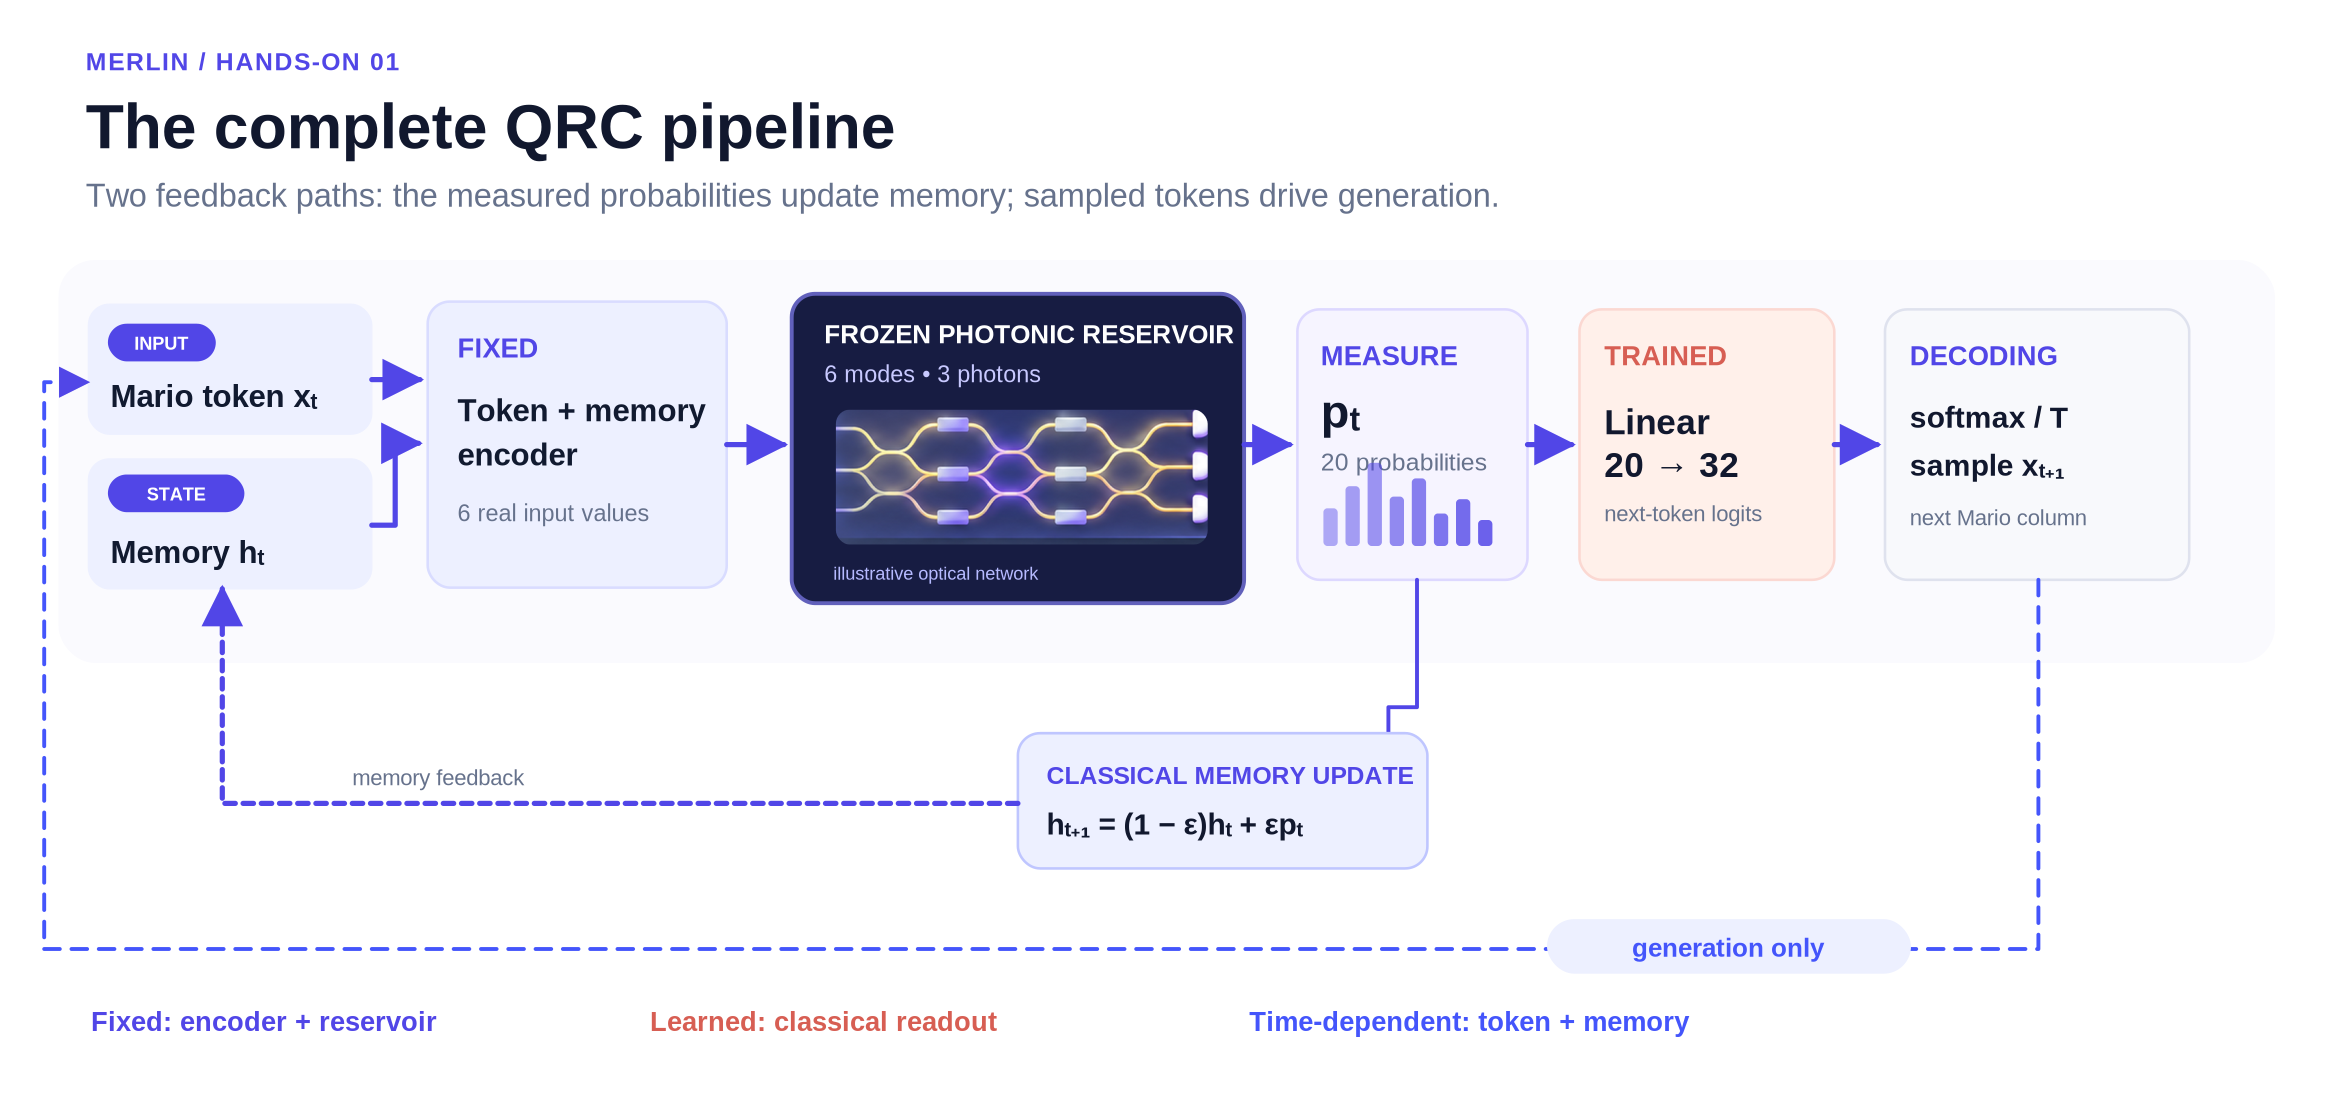

At each time step, the fixed encoder combines the **current Mario token** and the **classical memory** into six circuit inputs. The frozen MerLin reservoir produces 20 measured probabilities, and a **trained classical readout** maps them to 32 next-token logits.

**Two distinct feedback paths:** measured probabilities update the classical memory, while the **sampled next token** becomes the next input **during generation only**. In training, the next input comes from the original level (*teacher forcing*). The optical network drawn above is an illustration; the executable circuit is defined later.

| Component | Role | Optimized? |
|---|---|---|
| Token + memory encoder | Turns discrete tokens and history into six real inputs | No (fixed random) |
| MerLin photonic reservoir | Produces a 20-dimensional probability vector | **No (frozen)** |
| Classical linear readout | Predicts one of 32 possible next columns | **Yes** |
| Sampling temperature | Changes the generation distribution, after training | No |

**Quick question (30 s):** if the reservoir does not train, where can the model still learn a useful decision boundary?

## 1 · Preparation

This notebook follows the **MerLin 0.4.x** API used in both source workshops. A local Python kernel is sufficient; we simulate the photonic circuit, **not** a physical QPU.

In a **fresh** Python environment, run the next cell **once**. On a prepared training machine you can skip it. If installation requires a kernel restart, do that before proceeding.

In [ ]:
# Run once in a fresh environment. You can skip this on a preconfigured training machine.
%pip install -q "merlinquantum>=0.4,<0.5" matplotlib pandas pillow

In [ ]:
from __future__ import annotations

import base64
import io
import math
import random
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display

try:
    import torch
    import merlin as ML
except ImportError as exc:
    raise ImportError(
        "Missing MerLin or PyTorch: run the installation cell above, "
        "then restart the kernel if needed."
    ) from exc

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False})
print("MerLin:", getattr(ML, "__version__", "version not exposed"))
print("PyTorch:", torch.__version__)
print("Backend: local photonic simulation on CPU")

## 2 · Mario as a sequence (5–13 min)

The modified Super Mario Bros. level 1-2 is split into **16-pixel-wide columns**. Identical visual columns receive the same integer token.

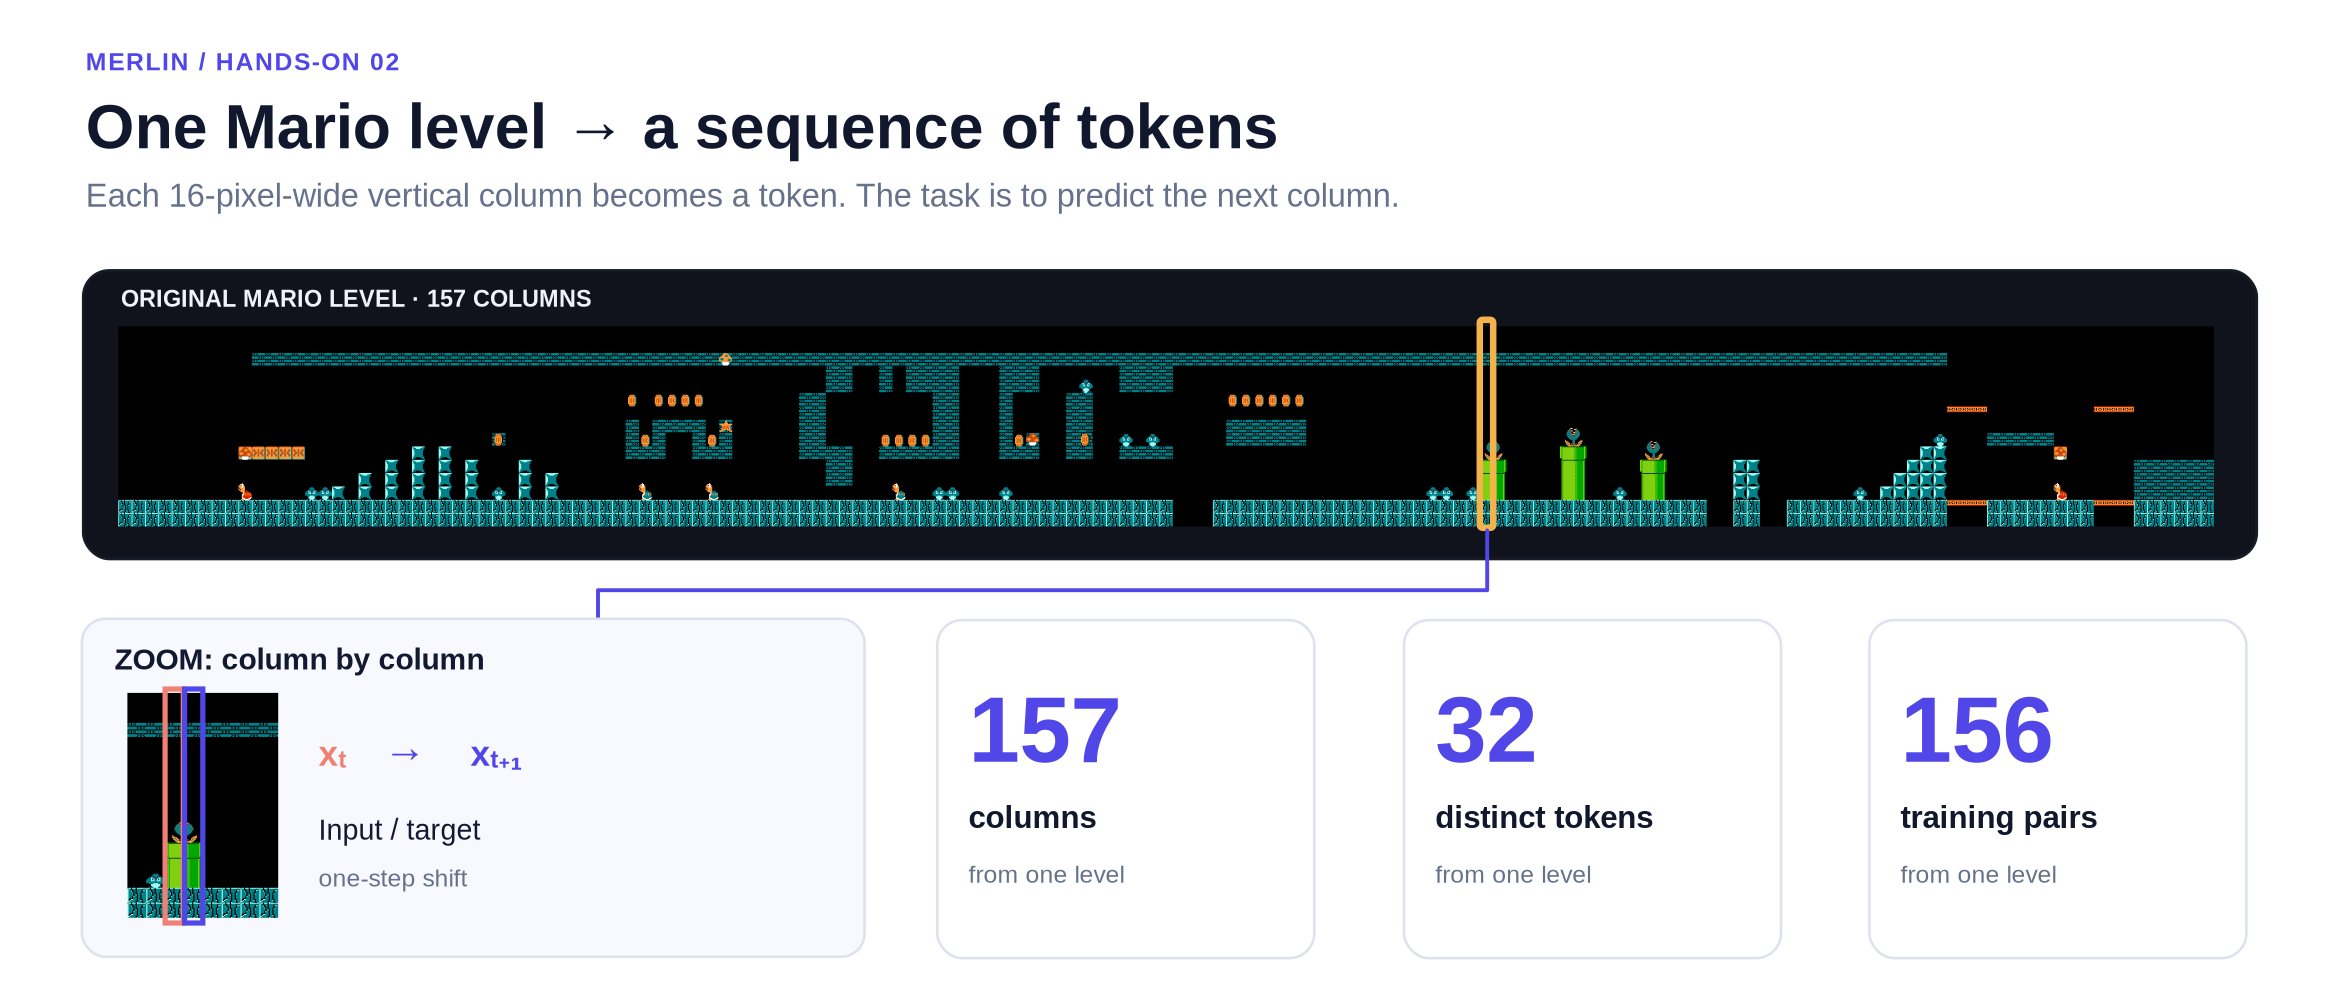

- **157** column positions in the original level;
- **32** distinct column types (vocabulary size);
- a generation task: predict token $x_{t+1}$ from token $x_t$ and a fading memory of the past.

The embedded PNG below is the original level. A tile atlas allows us to reconstruct any generated token sequence visually.

In [ ]:
# 🧰 Embedded data: Mario level 1-2 modified by the authors.

ORIGINAL_SEQUENCE = [
    0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 11, 11, 11, 11, 7, 7, 8, 6, 9,
    6, 10, 6, 12, 6, 12, 6, 10, 6, 17, 6, 10, 6, 9, 6, 6, 6, 6, 6,
    22, 15, 22, 20, 20, 22, 15, 31, 6, 6, 6, 6, 6, 23, 23, 26, 26, 6,
    6, 27, 15, 27, 27, 30, 30, 6, 6, 6, 30, 27, 29, 6, 6, 23, 24, 6,
    6, 28, 25, 28, 25, 5, 5, 5, 6, 21, 21, 21, 21, 21, 21, 6, 6, 6,
    6, 6, 6, 6, 6, 6, 7, 7, 6, 7, 13, 14, 6, 6, 6, 6, 18, 19, 6, 6,
    7, 6, 13, 14, 6, 6, 6, 5, 5, 10, 10, 5, 5, 6, 6, 6, 6, 6, 7, 6,
    8, 9, 10, 12, 16, 4, 4, 4, 3, 3, 3, 3, 3, 2, 0, 0, 4, 4, 4, 1,
    1, 1, 1, 1, 1,
]

_LEVEL_PNG_B64 = "..."
ORIGINAL_LEVEL_IMAGE = Image.open(
    io.BytesIO(base64.b64decode(_LEVEL_PNG_B64))
).convert("RGB")


def build_tile_atlas(image, sequence, tile_width=16):
    """Reconstruct feature_id -> 16 px column from the original level."""
    if image.width != tile_width * len(sequence):
        raise ValueError("Image width does not match the sequence length.")
    atlas = {}
    arrays = {}
    for index, feature in enumerate(sequence):
        tile = image.crop((index * tile_width, 0, (index + 1) * tile_width, image.height))
        tile_array = np.asarray(tile)
        if feature not in atlas:
            atlas[feature] = tile.copy()
            arrays[feature] = tile_array
        elif not np.array_equal(arrays[feature], tile_array):
            raise ValueError(f"Feature {feature} is not visually consistent.")
    return atlas


TILE_ATLAS = build_tile_atlas(ORIGINAL_LEVEL_IMAGE, ORIGINAL_SEQUENCE)


def render_level(sequence, atlas=TILE_ATLAS):
    """Assemble the tiles corresponding to a feature sequence."""
    tile_width = next(iter(atlas.values())).width
    height = next(iter(atlas.values())).height
    canvas = Image.new("RGB", (tile_width * len(sequence), height))
    for index, feature in enumerate(sequence):
        canvas.paste(atlas[int(feature)], (index * tile_width, 0))
    return canvas


display(ORIGINAL_LEVEL_IMAGE)

### ✍️ Exercise 1 — Build the next-token targets (2 min)

**Question:** given the sequence `[4, 4, 7, 2]`, which three `(input, target)` pairs does the model learn from?

In the draft cell below, replace `...` with a slice of `ORIGINAL_SEQUENCE`. You can skip it and run the checkpoint cell directly.

In [ ]:
# Draft for participants — not used by later cells.
inputs_student = np.asarray(ORIGINAL_SEQUENCE[:-1], dtype=np.int64)
targets_student = ...  # TODO: the sequence, shifted by one token

if targets_student is Ellipsis:
    print("Hint: the first target is ORIGINAL_SEQUENCE[1].")
else:
    assert len(inputs_student) == len(targets_student) == 156
    print("First pairs:", list(zip(inputs_student[:8], targets_student[:8])))

In [ ]:
# ✅ Checkpoint 1 — executable answer
sequence_length = len(ORIGINAL_SEQUENCE)
vocabulary_size = len(set(ORIGINAL_SEQUENCE))
inputs = np.asarray(ORIGINAL_SEQUENCE[:-1], dtype=np.int64)
targets = np.asarray(ORIGINAL_SEQUENCE[1:], dtype=np.int64)
assert sequence_length == 157 and vocabulary_size == 32
assert inputs.shape == targets.shape == (156,)
assert set(ORIGINAL_SEQUENCE) == set(range(vocabulary_size))

print(f"Level: {sequence_length} columns | Vocabulary: {vocabulary_size} tokens")
print("First (input, target) pairs:", list(zip(inputs[:10], targets[:10])))

fig, ax = plt.subplots(figsize=(9, 2.4))
most_common = Counter(ORIGINAL_SEQUENCE).most_common(12)
ax.bar([str(token) for token, _ in most_common], [n for _, n in most_common], color="#6250a9")
ax.set(xlabel="Token ID (12 most frequent)", ylabel="Count", title="The level is not a uniform sequence")
plt.show()

## 3 · The photonic reservoir with MerLin (13–25 min)

A MerLin **`CircuitBuilder`** specifies the photonic circuit; **`QuantumLayer`** exposes it as a PyTorch module. We make a random fixed interferometer, insert **angle encoding** for six real inputs, add two more fixed interferometers, and measure output probabilities.

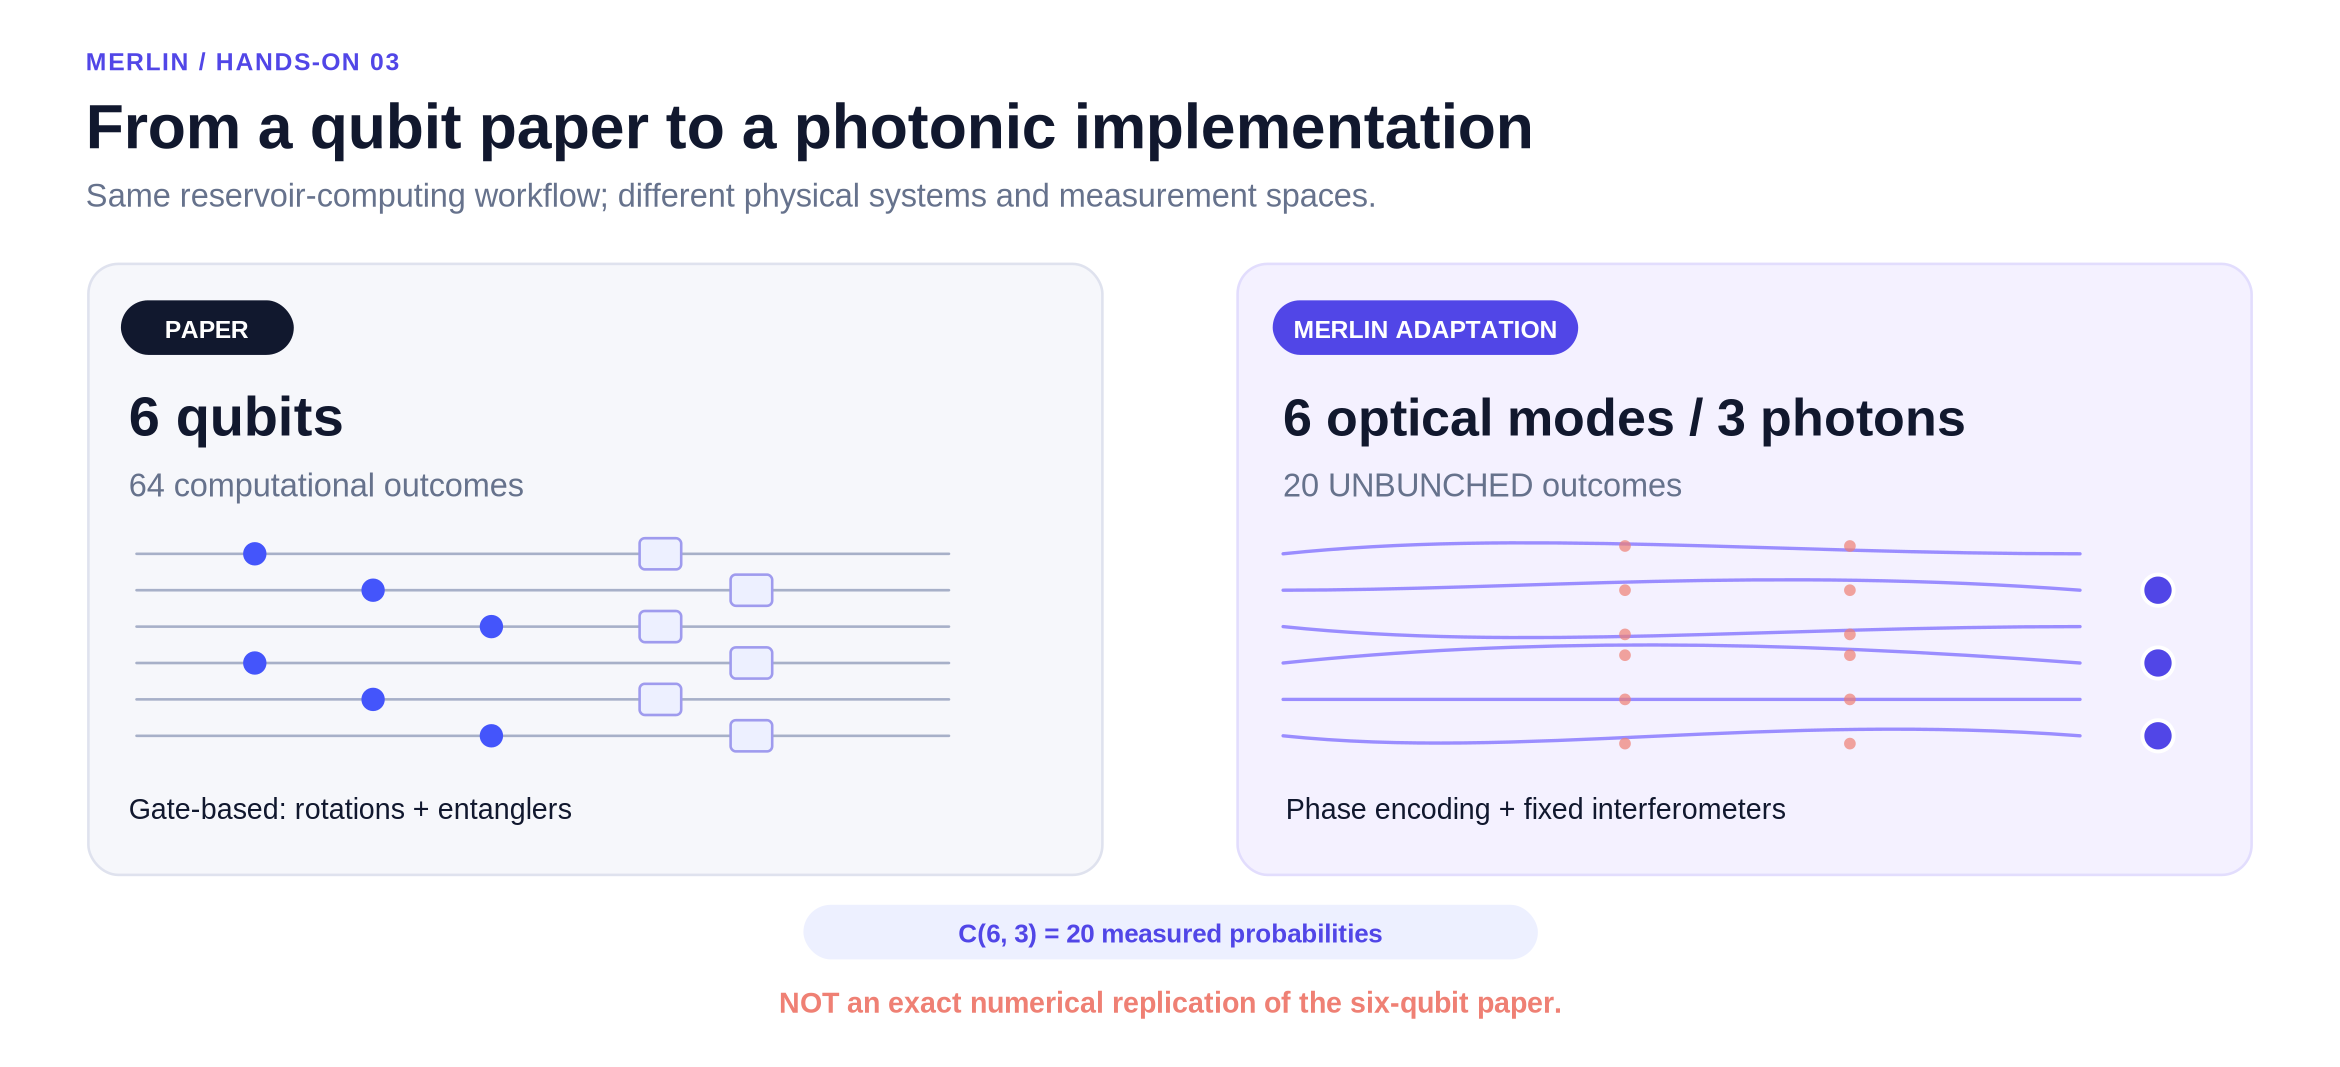

| Setting | Here | Why it matters |
|---|---:|---|
| Modes | 6 | Six real encoded inputs |
| Photons | 3 | Multiphoton interference |
| Computation space | `UNBUNCHED` | At most one photon per mode |
| Output dimension | $\binom{6}{3}=20$ | 20 probabilities for the readout |
| Trainable quantum parameters | **0** | The reservoir is deliberately frozen |

> **Analogy:** like a randomly initialized feature map in classical ML, the reservoir may make patterns easier to separate even when its own parameters never change. This **does not** establish that the quantum map outperforms classical alternatives.

### ✍️ Exercise 2 — Add the input encoding (3 min)

Complete the **one missing line** in `build_student_circuit` using:

`builder.add_angle_encoding(modes=..., name="qrc_input", scale=...)`

Use all six modes and a scale of `np.pi`. The function is only for practice; the checkpoint below will build the actual layer.

In [ ]:
N_MODES, N_PHOTONS = 6, 3

# Draft (the actual reservoir is built in the checkpoint below).
def build_student_circuit():
    builder = ML.CircuitBuilder(n_modes=N_MODES)
    builder.add_entangling_layer(trainable=False, name="pre")

    ...  # TODO: add angle encoding of all six modes

    builder.add_entangling_layer(trainable=False, name="post_1")
    builder.add_entangling_layer(trainable=False, name="post_2")
    return builder

In [ ]:
# ✅ Checkpoint 2 — the MerLin reservoir used for the rest of the training

def build_merlin_reservoir(n_modes=N_MODES, n_photons=N_PHOTONS):
    builder = ML.CircuitBuilder(n_modes=n_modes)
    builder.add_entangling_layer(trainable=False, name="pre")
    builder.add_angle_encoding(
        modes=list(range(n_modes)), name="qrc_input", scale=np.pi
    )
    builder.add_entangling_layer(trainable=False, name="post_1")
    builder.add_entangling_layer(trainable=False, name="post_2")

    layer = ML.QuantumLayer(
        input_size=n_modes,
        builder=builder,
        n_photons=n_photons,
        measurement_strategy=ML.MeasurementStrategy.probs(
            computation_space=ML.ComputationSpace.UNBUNCHED
        ),
        dtype=torch.float64,
    )
    for parameter in layer.parameters():
        parameter.requires_grad_(False)
    return layer.eval()

reservoir = build_merlin_reservoir()
RESERVOIR_DIM = reservoir.output_size
assert RESERVOIR_DIM == math.comb(N_MODES, N_PHOTONS) == 20

with torch.no_grad():
    probe = reservoir(torch.zeros((1, N_MODES), dtype=torch.float64))
assert tuple(probe.shape) == (1, 20)
assert torch.isclose(probe.sum(), torch.tensor(1., dtype=torch.float64), atol=1e-5)
assert not any(p.requires_grad for p in reservoir.parameters())

print("Input shape: (batch, 6) | Output shape:", tuple(probe.shape))
print("Probability sum:", float(probe.sum()))
print("Trainable circuit parameters:", sum(p.numel() for p in reservoir.parameters() if p.requires_grad))

### Visual check — does changing the input affect the output?

Sweep one input coordinate from `-1` to `1` while holding the others at zero. The heatmap shows how the **20 measurement probabilities** respond. **Question:** why is this a feature map, rather than a trained classifier?

In [ ]:
sweep = np.linspace(-1.0, 1.0, 80)  # fewer points keeps the live demo responsive
batch = np.zeros((len(sweep), N_MODES))
batch[:, 0] = sweep
with torch.no_grad():
    sweep_probabilities = reservoir(torch.as_tensor(batch, dtype=torch.float64)).detach().cpu().numpy()

fig, ax = plt.subplots(figsize=(8.2, 3.1))
img = ax.imshow(sweep_probabilities.T, aspect="auto", origin="lower",
                extent=[-1, 1, -0.5, RESERVOIR_DIM - 0.5], cmap="viridis")
ax.set(xlabel="Input on mode 0 (other modes = 0)", ylabel="Photonic output feature",
       title="A fixed photonic circuit transforms its inputs")
fig.colorbar(img, ax=ax, label="Measurement probability")
plt.show()

## 4 · Add memory to the model (25–31 min)

The reservoir accepts **six real values**, but our model has both a discrete token and a 20-dimensional memory vector. We therefore use two **fixed** random components:

- `feature_book`: a **32 × 6** lookup table that assigns each Mario token six input values;
- `hidden_projection`: a **20 × 6** matrix that compresses the memory to six inputs.

Both are initialized once and never trained. The encoder combines them as follows:

$$u_t = \tanh\left(E[x_t] + \sqrt{20}\,h_t P\right)$$

Then the photonic circuit produces $p_t$ and we update the memory:

$$h_{t+1} = (1-\varepsilon)h_t+\varepsilon p_t \qquad \varepsilon=0.3$$

**Interpretation:** each step retains 70% of the previous memory and introduces 30% of the new probability vector. The model can therefore depend on more than one column of context.

In [ ]:
# Provided encoder: token + memory -> 6 values in [-1, 1]
class FixedQRCEncoder:
    def __init__(self, num_features, n_modes, reservoir_dim, seed=SEED):
        rng = np.random.default_rng(seed)
        self.feature_book = rng.uniform(-1, 1, size=(num_features, n_modes))
        self.hidden_projection = rng.normal(0, 1, size=(reservoir_dim, n_modes))
        self.reservoir_dim = reservoir_dim

    def __call__(self, token, hidden):
        token_signal = self.feature_book[int(token)]
        memory_signal = np.sqrt(self.reservoir_dim) * (hidden @ self.hidden_projection)
        return np.tanh(token_signal + memory_signal)

encoder = FixedQRCEncoder(vocabulary_size, N_MODES, RESERVOIR_DIM)
initial_hidden = np.full(RESERVOIR_DIM, 1.0 / RESERVOIR_DIM)
print("Encoded six-input vector:", encoder(ORIGINAL_SEQUENCE[0], initial_hidden).round(3))

### ✍️ Exercise 3 — Update the memory (2 min)

Complete $h_{t+1}=(1-\varepsilon)h_t+\varepsilon p_t$. What should happen to the memory if you set $\varepsilon$ near **0**? And near **1**?

In [ ]:
# Draft — not used by later cells.
def update_hidden_student(hidden, probabilities, epsilon=0.3):
    return ...  # TODO: (1 - epsilon) * ... + epsilon * ...

In [ ]:
# ✅ Checkpoint 3 — executable answer
def update_hidden(hidden, probabilities, epsilon=0.3):
    if not 0.0 <= epsilon <= 1.0:
        raise ValueError("epsilon must be between 0 and 1")
    updated = (1.0 - epsilon) * hidden + epsilon * probabilities
    return updated / updated.sum()

sample_probabilities = np.zeros(RESERVOIR_DIM)
sample_probabilities[3] = 1.0
for leak in [0.1, 0.3, 0.9]:
    updated = update_hidden(initial_hidden, sample_probabilities, epsilon=leak)
    print(f"epsilon={leak}: memory[3]={updated[3]:.3f}, sum={updated.sum():.3f}")

## 5 · Teacher forcing and readout training (31–38 min)

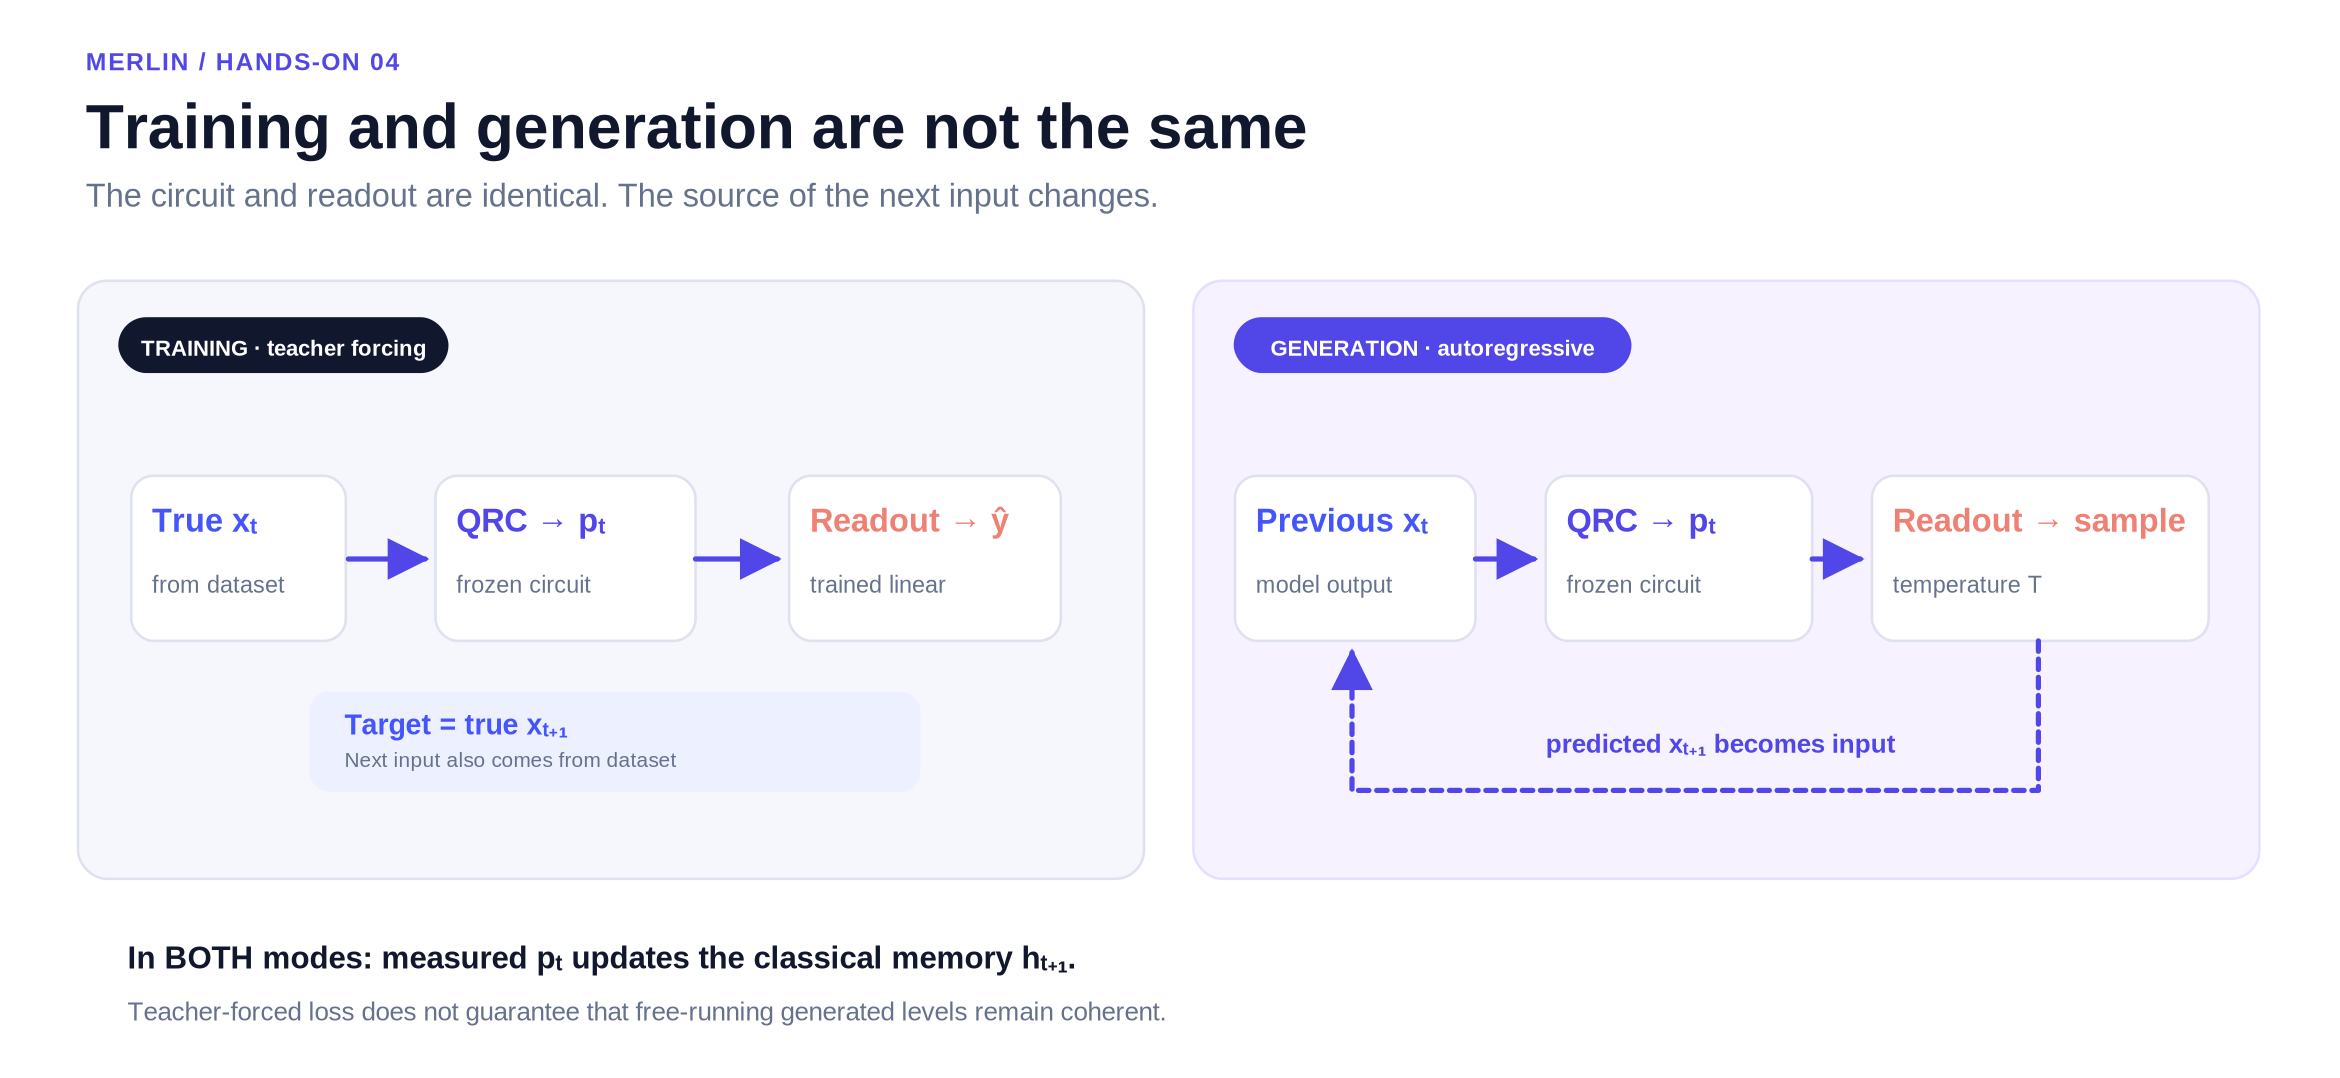

**Teacher forcing:** during training, we give the model the **actual** column $x_t$, not its own generated output. The frozen reservoir extracts one 20-dimensional vector $p_t$ per time step, resulting in a feature matrix of shape **156 × 20**.

We then train a conventional `torch.nn.Linear(20, 32)` to classify the next token using cross-entropy. This layer has **672 trainable parameters** ($20\times32 + 32$). Importantly, the optimizer never sees quantum circuit parameters.

**Discussion:** if training loss decreases, does that mean the generated levels will always be playable? (No: teacher forcing differs from closed-loop generation.)

In [ ]:
# Provided helpers: probability extraction + teacher forcing + classical training

def reservoir_probabilities(layer, encoded_input):
    x = torch.as_tensor(encoded_input, dtype=torch.float64).unsqueeze(0)
    with torch.no_grad():
        probabilities = layer(x).squeeze(0).detach().cpu().numpy()
    probabilities = np.clip(probabilities.astype(float), 0.0, None)
    if probabilities.sum() <= 0:
        raise ValueError("The reservoir returned zero total probability")
    return probabilities / probabilities.sum()


def teacher_forced_features(layer, qrc_encoder, sequence, epsilon=0.3):
    hidden = np.full(layer.output_size, 1.0 / layer.output_size)
    features = []
    for token in sequence[:-1]:
        probabilities = reservoir_probabilities(layer, qrc_encoder(token, hidden))
        features.append(probabilities)
        hidden = update_hidden(hidden, probabilities, epsilon)
    return np.asarray(features)


def train_readout(features, target_tokens, epochs=200, lr=0.05, seed=SEED):
    X = torch.as_tensor(features, dtype=torch.float64)
    y = torch.as_tensor(target_tokens, dtype=torch.long)
    torch.manual_seed(seed)
    model = torch.nn.Linear(X.shape[1], vocabulary_size, dtype=torch.float64)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = torch.nn.functional.cross_entropy(model(X), y)
        loss.backward()
        optimizer.step()
        history.append(float(loss.item()))
    return model.eval(), history

start = time.perf_counter()
quantum_features = teacher_forced_features(reservoir, encoder, ORIGINAL_SEQUENCE)
readout, loss_history = train_readout(quantum_features, targets)
print(f"Feature matrix: {quantum_features.shape}")
print(f"Readout parameters: {sum(p.numel() for p in readout.parameters())}")
print(f"Training loss: {loss_history[0]:.3f} → {loss_history[-1]:.3f}")
print(f"Elapsed: {time.perf_counter() - start:.1f}s (depends on CPU)")
assert quantum_features.shape == (156, 20)
assert sum(p.numel() for p in readout.parameters()) == 672

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
axes[0].imshow(quantum_features.T, aspect="auto", cmap="viridis")
axes[0].set(title="Frozen reservoir features", xlabel="Mario column t", ylabel="Feature index")
axes[1].plot(loss_history, color="#6250a9")
axes[1].set(title="Training the classical readout", xlabel="Epoch", ylabel="Cross-entropy")
plt.tight_layout()
plt.show()

## 6 · Generate a new level (38–48 min)

Training used the true sequence. Generation works differently: start from one column and **feed every prediction back in**. A small mistake can therefore affect the rest of the generated level.

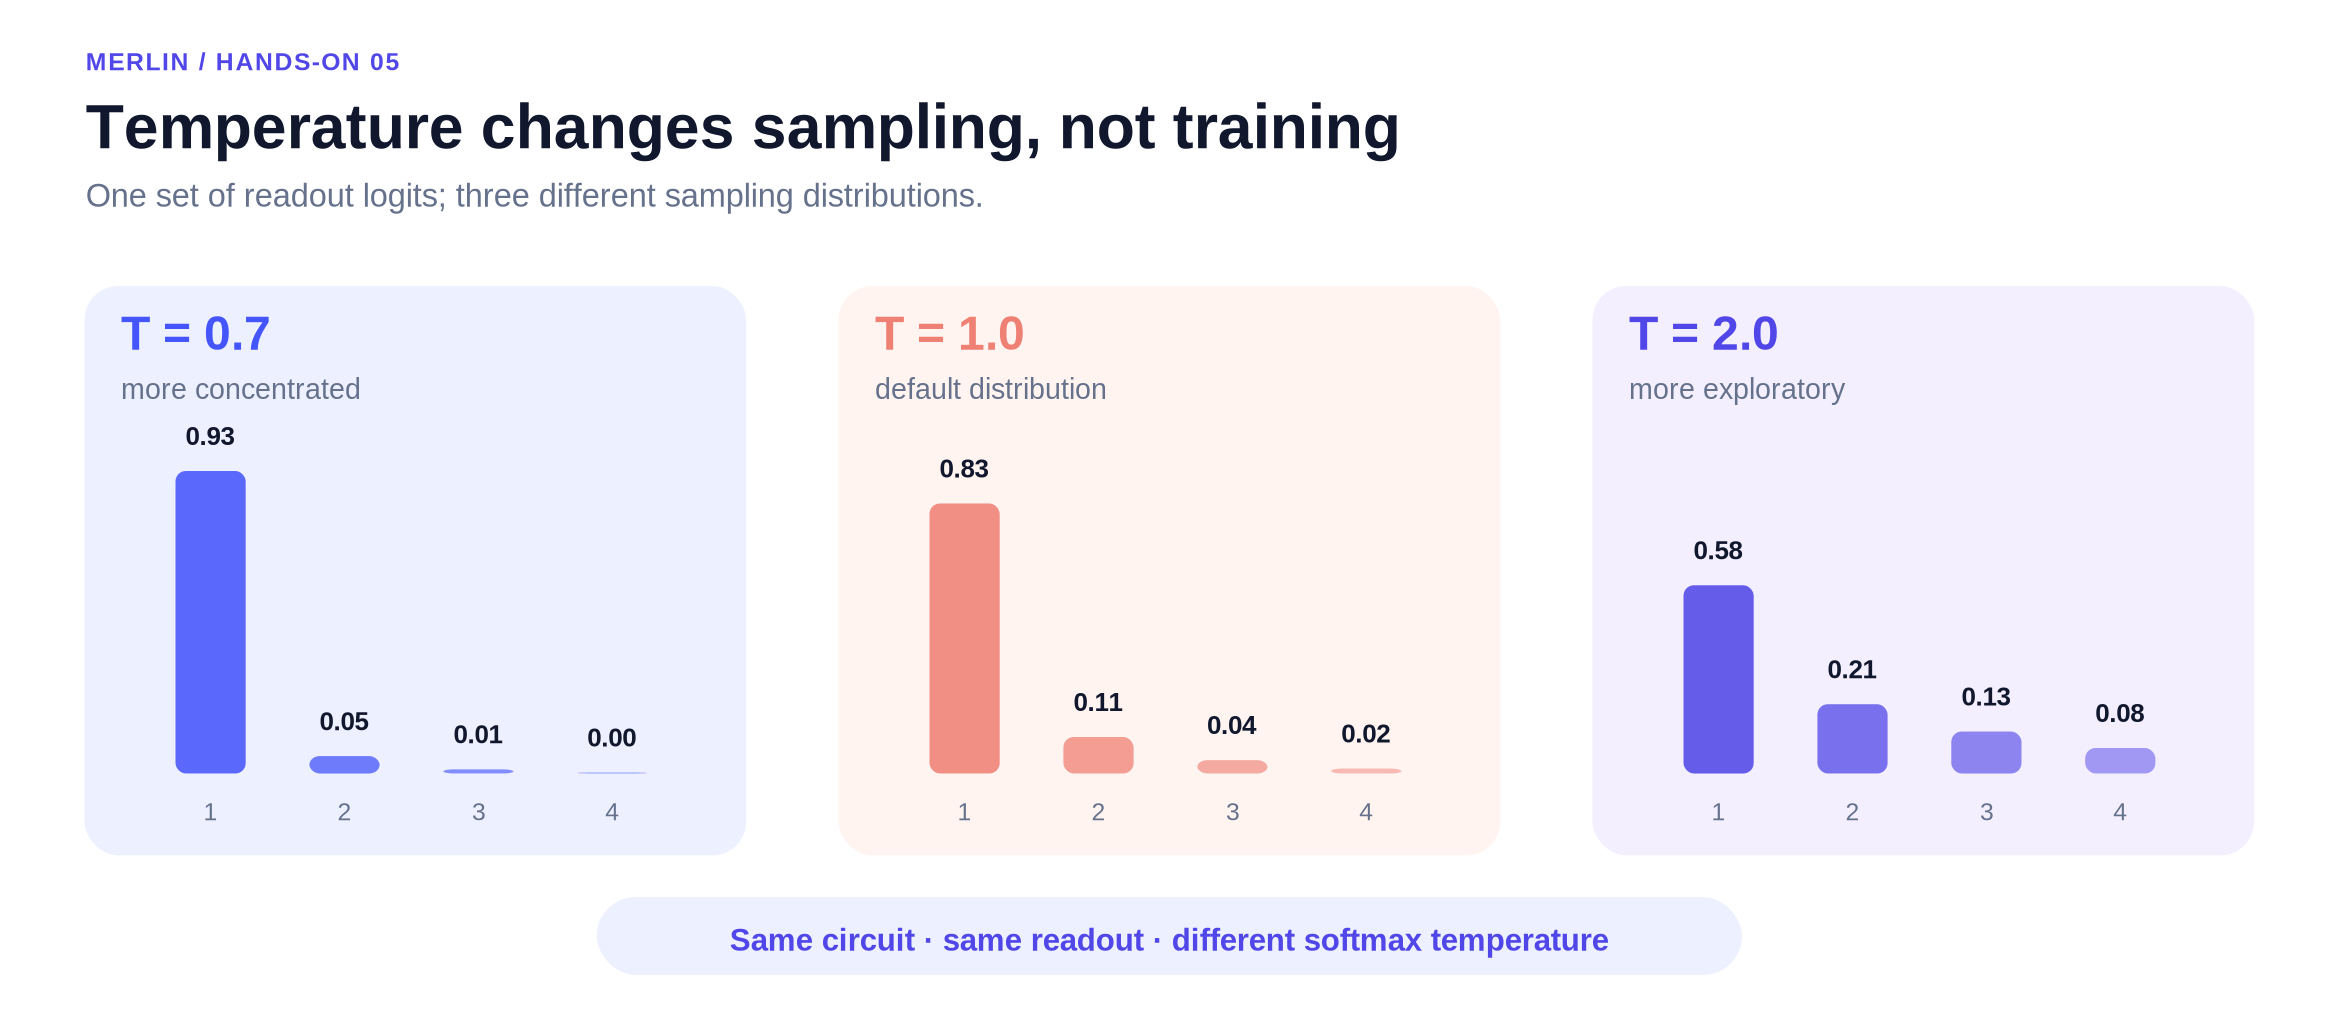

Sampling temperature rescales the logits:

$$P(x_{t+1}=k) = \operatorname{softmax}(y_t/T)_k$$

- **Low $T$:** more concentrated distribution, more predictable tokens.
- **High $T$:** flatter distribution, more diverse tokens.
- **$T$ changes generation, not training.** The reservoir and readout weights stay unchanged.

**Predict before running:** which of $T=0.7$, $T=1.0$, $T=2.0$ will produce the greatest originality? Will that also mean fewer gameplay errors?

*The bar charts above are a conceptual example using the same four logits at three temperatures—not predictions from the trained Mario model.*

### ✍️ Exercise 4 — Temperature sampling (2 min)

Complete the `scaled = ...` line in the draft. What happens at a very small temperature? **Hint:** divide the logits by temperature before softmax.

In [ ]:
# Draft — not used by later cells.
def softmax_temperature_student(logits, temperature=1.0):
    assert temperature > 0
    scaled = ...  # TODO: logits / temperature
    if scaled is Ellipsis:
        return None
    scaled = scaled - np.max(scaled)
    exps = np.exp(scaled)
    return exps / exps.sum()

In [ ]:
# ✅ Checkpoint 4 — working functions
def softmax_temperature(logits, temperature=1.0):
    if temperature <= 0:
        raise ValueError("Temperature must be positive")
    z = np.asarray(logits, dtype=float) / temperature
    z = z - np.max(z)  # numerical stability
    exps = np.exp(z)
    return exps / exps.sum()


def generate_level(layer, qrc_encoder, classical_readout, length, temperature,
                   seed, epsilon=0.3, first_token=0):
    rng = np.random.default_rng(seed)
    hidden = np.full(layer.output_size, 1.0 / layer.output_size)
    generated = [int(first_token)]
    for _ in range(length - 1):
        p = reservoir_probabilities(layer, qrc_encoder(generated[-1], hidden))
        hidden = update_hidden(hidden, p, epsilon)
        with torch.no_grad():
            logits = classical_readout(
                torch.as_tensor(p, dtype=torch.float64)
            ).detach().cpu().numpy()
        next_token = rng.choice(len(logits), p=softmax_temperature(logits, temperature))
        generated.append(int(next_token))
    return generated

example_logits = np.array([3.0, 1.0, 0.0, -1.0])
for T in [0.2, 1.0, 3.0]:
    print(f"T={T:<3}: probabilities {softmax_temperature(example_logits, T).round(3)}")

### Live experiment: change only the temperature

Start with **three generated levels per temperature**. That is enough to visualize different behaviors in class, but **not** enough for statistical conclusions. Set `N_GENERATIONS = 10` **after** the session for a less noisy comparison.

The generation loop calls the simulated photonic reservoir repeatedly and may take a little time on a CPU.

In [ ]:
TEMPERATURES = [0.7, 1.0, 2.0]
N_GENERATIONS = 3  # live-training default; use >=10 for follow-up analysis

start = time.perf_counter()
qrc_generations = {}
for T in TEMPERATURES:
    qrc_generations[T] = [
        generate_level(reservoir, encoder, readout, sequence_length,
                       temperature=T, seed=SEED + 1000 + int(100 * T) + i,
                       first_token=ORIGINAL_SEQUENCE[0])
        for i in range(N_GENERATIONS)
    ]
    print(f"T={T}: {N_GENERATIONS} generated levels")
print(f"Generation time: {time.perf_counter() - start:.1f}s")

fig, axes = plt.subplots(len(TEMPERATURES) + 1, 1, figsize=(12, 6.3))
for ax, (label, level) in zip(
    axes,
    [("Original", ORIGINAL_SEQUENCE)]
    + [(f"MerLin QRC — T={T}", qrc_generations[T][0]) for T in TEMPERATURES]
):
    ax.imshow(render_level(level))
    ax.set_title(label, loc="left", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7 · Do the levels make sense? (48–57 min)

A visually new level is not necessarily a good level. Always compare against simple baselines:

- **Uncorrelated:** independently sample each token from its global frequency. High diversity is possible, but local structure can break.
- **Markov (bigram):** sample the next token given *only* the previous token. It is simple but can preserve local adjacency well.

Our two evaluation measures are drawn from the source reproduction:

**Originality at length $L$**: the proportion of generated $L$-token windows absent from the original level. We report $L=2$ (local novelty) and $L=10$ (longer motifs).

**Broken-transition rate**: the fraction of failed *applicable* rule checks across generated levels (paired pipe halves and unobstructed passages). **Lower** is better. The table also reports the number of checks evaluated, because some sequences may contain no applicable configuration. This is a **partial rule-based proxy**, not a complete playability test.

The comparison is most useful as a trade-off: can we improve originality **without** creating too many invalid local transitions?

**Fair live comparison:** use `N_GENERATIONS` levels for Markov, uncorrelated, and **each** QRC temperature. With three samples per method, interpret results as a classroom illustration, not statistically reliable evidence. Increase the sample count and repeat across seeds after the training.

In [ ]:
# Provided baseline generators (no artificial end-to-start transition in Markov)
def generate_uncorrelated(sequence, length, rng):
    values, counts = np.unique(sequence, return_counts=True)
    return rng.choice(values, size=length, p=counts / counts.sum()).astype(int).tolist()


def fit_markov(sequence):
    transitions = defaultdict(Counter)
    for current, nxt in zip(sequence[:-1], sequence[1:]):
        transitions[int(current)][int(nxt)] += 1
    return transitions


def generate_markov(sequence, length, rng, transitions):
    generated = [int(rng.choice(sequence))]
    fallback, fallback_counts = np.unique(sequence, return_counts=True)
    for _ in range(length - 1):
        c = transitions.get(generated[-1])
        if not c:
            next_token = rng.choice(fallback, p=fallback_counts / fallback_counts.sum())
        else:
            values = np.asarray(sorted(c), dtype=int)
            counts = np.asarray([c[v] for v in values], dtype=float)
            next_token = rng.choice(values, p=counts / counts.sum())
        generated.append(int(next_token))
    return generated

baseline_rng = np.random.default_rng(SEED)
transitions = fit_markov(ORIGINAL_SEQUENCE)
BASELINE_SAMPLES = N_GENERATIONS  # match the number of levels per QRC temperature
uncorrelated_generations = [
    generate_uncorrelated(ORIGINAL_SEQUENCE, sequence_length, baseline_rng)
    for _ in range(BASELINE_SAMPLES)
]
markov_generations = [
    generate_markov(ORIGINAL_SEQUENCE, sequence_length, baseline_rng, transitions)
    for _ in range(BASELINE_SAMPLES)
]
print(f"Baselines: {len(markov_generations)} Markov + {len(uncorrelated_generations)} uncorrelated")

In [ ]:
# Metrics adapted from the original workshop/reproduction

def count_ngrams(sequence, length):
    return Counter(tuple(sequence[i:i + length])
                   for i in range(len(sequence) - length + 1))


def originality(generated_sequences, original, length):
    reference = count_ngrams(original, length)
    novel, total = 0, 0
    for generated in generated_sequences:
        for ngram, count in count_ngrams(generated, length).items():
            total += count
            novel += count * (ngram not in reference)
    return novel / total if total else np.nan


def mario_rule_2(i, sequence):
    # Checks only the Mario rules relevant to certain local configurations.
    if i <= 0 or i >= len(sequence) - 1:
        return None
    current = int(sequence[i])
    before = int(sequence[i - 1])
    after = int(sequence[i + 1])
    if current == 14: return before == 13  # right half, small pipe
    if current == 13: return after == 14   # left half, small pipe
    if current == 19: return before == 18  # right half, large pipe
    if current == 18: return after == 19   # left half, large pipe
    if current == 30:
        blockers = {1, 10, 12, 16, 18, 19}
        return before not in blockers and after not in blockers
    return None


def applicable_rule_checks(sequence):
    """List only the rule checks that are relevant to this generated sequence."""
    outcomes = [mario_rule_2(i, sequence) for i in range(len(sequence))]
    return [value for value in outcomes if value is not None]


def broken_rate(sequence):
    checks = applicable_rule_checks(sequence)
    return 1.0 - float(np.mean(checks)) if checks else np.nan


def score(label, generated_sequences, T=np.nan):
    # Pool applicable checks so that the reported rate truly is the fraction
    # of all checked local transitions that fail (not a mean of per-level rates).
    check_lists = [applicable_rule_checks(seq) for seq in generated_sequences]
    all_checks = [outcome for checks in check_lists for outcome in checks]
    return {
        "generator": label,
        "temperature": T,
        "orig_L2": originality(generated_sequences, ORIGINAL_SEQUENCE, 2),
        "orig_L10": originality(generated_sequences, ORIGINAL_SEQUENCE, 10),
        "broken_rate": 1.0 - float(np.mean(all_checks)) if all_checks else np.nan,
        "n_rule_checks": len(all_checks),
        "n_evaluable_levels": sum(bool(checks) for checks in check_lists),
        "n_levels": len(generated_sequences),
    }


In [ ]:
rows = [
    score("Original", [ORIGINAL_SEQUENCE]),
    score("Uncorrelated", uncorrelated_generations),
    score("Markov", markov_generations),
]
rows += [score("MerLin QRC", qrc_generations[T], T=T) for T in TEMPERATURES]
results = pd.DataFrame(rows)
display(results.round(3))
print('Rule coverage matters: n_rule_checks = 0 means broken_rate is undefined for that method.')

fig, ax = plt.subplots(figsize=(7.7, 4.6))
colors = {"Original": "#222222", "Uncorrelated": "#777777",
          "Markov": "#2d9468", "MerLin QRC": "#6250a9"}
markers = {"Original": "*", "Uncorrelated": "s", "Markov": "^", "MerLin QRC": "o"}
for _, r in results.iterrows():
    if np.isnan(r["broken_rate"]):
        continue
    ax.scatter(r["broken_rate"], r["orig_L2"],
               c=colors[r["generator"]], marker=markers[r["generator"]], s=100)
    label = r["generator"] if pd.isna(r["temperature"]) else f"QRC T={r['temperature']}"
    ax.annotate(label, (r["broken_rate"], r["orig_L2"]),
                xytext=(6, 5), textcoords="offset points", fontsize=9)
ax.set(xlabel="Broken-transition rate ↓ (lower is better)",
       ylabel="Originality at L=2 ↑ (higher is more novel)",
       title="New ≠ good: novelty versus local coherence")
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(-0.05, 1.05)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8 · Interpret and conclude (57–60 min)

**Discuss (in pairs or as a group):**

1. Which temperature gives the most **novel** local transitions in your run? Does it also have the fewest **broken** transitions?
2. Does the photonic QRC clearly beat the **Markov** baseline on *both* metrics? If not, what would you need to change or investigate?
3. Why can we tune temperature **without retraining**?

**Three takeaways**

- `CircuitBuilder` + `QuantumLayer` let you connect a photonic feature extractor to a regular PyTorch model.
- The **fixed** quantum reservoir maps a token and its memory into a probability vector; the small **classical** readout does the learning.
- More randomness can make levels more original but not necessarily more coherent. Baselines and validation matter more than a striking image.

**Do not overclaim:** this is a CPU simulation of a photonic adaptation with **one reservoir seed**, **one short training level** and **a few generated samples**. It does **not** demonstrate quantum advantage, robust gameplay quality, or performance on hardware.

**Suggested follow-up after the class:** raise `N_GENERATIONS` to 20; repeat over several random seeds; compare means and variability. Then add a similarly sized **classical random reservoir** as a control experiment (present in the 20-minute source notebook).

## Source material and references

This 60-minute notebook is adapted from the two materials supplied for this training:

- `MerLin_QRC_Level_Generation_Workshop_2h_corrected.ipynb` — longer guided exercises and metric definitions.
- `MerLin_QRC_Mario_Demo_20min.ipynb` — shorter demonstration sequence, heatmaps and baseline approach.

Scientific and technical background:

- Ferreira, Fromholz, Shaji & Wootton, *Level Generation with Quantum Reservoir Computing*, [arXiv:2505.13287](https://arxiv.org/abs/2505.13287).
- [MerLin reproduced-papers repository — QRC level generation](https://github.com/merlinquantum/reproduced_papers/tree/main/papers/qrc_level_generation).
- [MerLin 0.4 documentation](https://merlinquantum.ai/0.4/).

**Training environment:** MerLin 0.4.x + PyTorch; all Mario image and sequence data are embedded.